# Практическая работа №7
## Случайный лес — Вариант B

**Датасет:** Titanic

**Цель:** обучить одиночное дерево решений и случайный лес, подобрать гиперпараметры с помощью кросс-валидации, сравнить качество моделей и изучить важность признаков.

**Целевая переменная:** Survived (0 — погиб, 1 — выжил).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    cross_val_score
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
df = pd.read_csv("../data/titanic.csv")

display(df.head())

print("Размер таблицы:", df.shape)
print("\nПропущенные значения:")
print(df.isnull().sum())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Размер таблицы: (891, 12)

Пропущенные значения:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [3]:
numeric_features = ["Age", "Fare", "SibSp", "Parch"]

categorical_features = [
    "Sex",
    "Pclass",
    "Embarked"
]

features = numeric_features + categorical_features

X = df[features].copy()
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (712, 7)
Test: (179, 7)


### Подготовка данных

Данные разделены на обучающую и тестовую выборки в соотношении 80/20.

Используется стратификация для сохранения соотношения выживших и погибших.

Для обучения выбраны числовые и категориальные признаки. Заполнение пропусков и кодирование категорий будут выполняться внутри Pipeline, чтобы избежать утечки информации из тестовой выборки.

In [4]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [5]:
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

print("Дерево решений обучено!")

Дерево решений обучено!


In [6]:
forest_default = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42
    ))
])

forest_default.fit(X_train, y_train)

forest_pred = forest_default.predict(X_test)

print("Случайный лес обучен!")

Случайный лес обучен!


### Дерево решений и случайный лес

Одиночное дерево решений последовательно разделяет данные по признакам и может переобучаться.

Случайный лес объединяет предсказания нескольких деревьев, обученных на случайных подвыборках данных и признаков. Это часто помогает уменьшить разброс модели.

Для базового случайного леса используются 100 деревьев — стандартное значение, которое далее сравнивается с другими вариантами при настройке гиперпараметров.

In [7]:
forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42
    ))
])

param_grid = {
    "classifier__n_estimators": [50, 100, 150],
    "classifier__max_depth": [5, 10, None],
    "classifier__min_samples_leaf": [1, 3, 5]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    forest_pipeline,
    param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_forest = grid_search.best_estimator_

print("Лучшие параметры:")
print(grid_search.best_params_)

print("Лучший F1 на CV:",
      round(grid_search.best_score_, 3))

Лучшие параметры:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 150}
Лучший F1 на CV: 0.744


In [8]:
def evaluate_model(name, model):
    pred = model.predict(X_test)

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred)
    }

comparison = pd.DataFrame([
    evaluate_model("Decision Tree", tree_model),
    evaluate_model("Random Forest Default", forest_default),
    evaluate_model("Random Forest Tuned", best_forest)
])

display(comparison.round(3))

,Model,Accuracy,Precision,Recall,F1
0,Decision Tree,0.832,0.810,0.739,0.773
1,Random Forest Default,0.804,0.774,0.696,0.733
2,Random Forest Tuned,0.821,0.849,0.652,0.738


### Сравнение моделей

В работе сравниваются одиночное дерево решений, случайный лес с базовыми параметрами и случайный лес с подобранными гиперпараметрами.

Для оценки используются Accuracy, Precision, Recall и F1.

Основной метрикой при настройке выбран F1, поскольку он учитывает как точность положительных предсказаний, так и полноту обнаружения выживших пассажиров.

Все модели сравниваются на одинаковой тестовой выборке.

In [9]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_forest,
    X_train,
    y_train,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df)

,Feature,Importance
4,Sex,0.333566
5,Pclass,0.150213
1,Fare,0.099622
0,Age,0.075699
6,Embarked,0.047145
3,Parch,0.021220
2,SibSp,0.017813


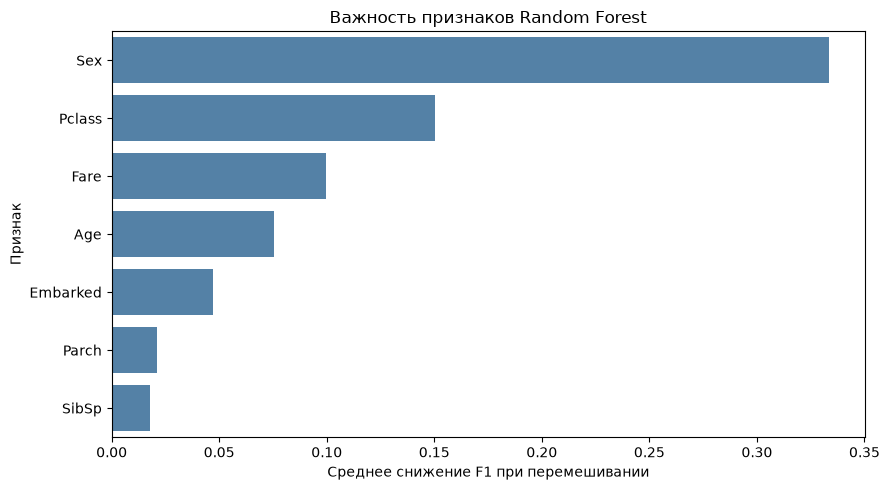

In [10]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Важность признаков Random Forest")
plt.xlabel("Среднее снижение F1 при перемешивании")
plt.ylabel("Признак")

plt.tight_layout()
plt.show()

### Анализ важности признаков

Важность признаков оценена методом permutation importance. Метод проверяет изменение качества модели при случайном перемешивании отдельного признака.

Чем сильнее снижается F1, тем больше модель зависит от данного признака на оцениваемых данных.

Между связанными признаками важность может распределяться, поэтому низкая оценка не всегда означает, что признак бесполезен.

Полученные результаты будут использованы для эксперимента с сокращением набора признаков.

In [11]:
least_important = importance_df.tail(2)["Feature"].tolist()

reduced_features = [
    col for col in features
    if col not in least_important
]

print("Удаляемые признаки:", least_important)
print("Оставшиеся признаки:", reduced_features)

Удаляемые признаки: ['Parch', 'SibSp']
Оставшиеся признаки: ['Age', 'Fare', 'Sex', 'Pclass', 'Embarked']


In [12]:
from sklearn.base import clone

reduced_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline,
     [f for f in numeric_features if f in reduced_features]),
    ("cat", categorical_pipeline,
     [f for f in categorical_features if f in reduced_features])
])

reduced_forest = Pipeline([
    ("preprocessor", reduced_preprocessor),
    ("classifier", clone(best_forest.named_steps["classifier"]))
])

cv_full = cross_val_score(
    clone(best_forest),
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

cv_reduced = cross_val_score(
    reduced_forest,
    X_train[reduced_features],
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

print("Полный набор — F1 CV:", round(cv_full.mean(), 3))
print("Сокращённый набор — F1 CV:", round(cv_reduced.mean(), 3))

Полный набор — F1 CV: 0.744
Сокращённый набор — F1 CV: 0.742


In [13]:
feature_comparison = pd.DataFrame({
    "Model": ["Все признаки", "Сокращённый набор"],
    "F1_CV": [cv_full.mean(), cv_reduced.mean()],
    "Std_CV": [cv_full.std(), cv_reduced.std()],
    "Features": [len(features), len(reduced_features)]
})

display(feature_comparison.round(3))

,Model,F1_CV,Std_CV,Features
0,Все признаки,0.744,0.036,7
1,Сокращённый набор,0.742,0.026,5


### Эксперимент по удалению признаков

Для эксперимента были выбраны два признака с наименьшей оценкой permutation importance.

Случайный лес обучается на сокращённом наборе и сравнивается с полной моделью с помощью одинаковой схемы кросс-валидации.

Если F1 сокращённой модели остаётся близким к результату полной модели, это означает, что удаление признаков может быть допустимо.

Однако вывод ограничен проведённым экспериментом. Для подтверждения устойчивости результата потребовалась бы дополнительная проверка на других разбиениях.

In [14]:
use_reduced = cv_reduced.mean() >= cv_full.mean() - 0.01

if use_reduced:
    final_model = clone(reduced_forest)
    final_features = reduced_features
else:
    final_model = clone(best_forest)
    final_features = features

final_model.fit(
    X_train[final_features],
    y_train
)

final_pred = final_model.predict(X_test)

print("Итоговые признаки:", final_features)
print("Количество деревьев:",
      final_model.named_steps["classifier"].n_estimators)

print("\nИтоговое качество на Test:")
print(classification_report(
    y_test,
    final_pred,
    target_names=["Погиб", "Выжил"]
))

Итоговые признаки: ['Age', 'Fare', 'Sex', 'Pclass', 'Embarked']
Количество деревьев: 150

Итоговое качество на Test:
              precision    recall  f1-score   support

       Погиб       0.80      0.89      0.84       110
       Выжил       0.79      0.64      0.70        69

    accuracy                           0.79       179
   macro avg       0.79      0.76      0.77       179
weighted avg       0.79      0.79      0.79       179



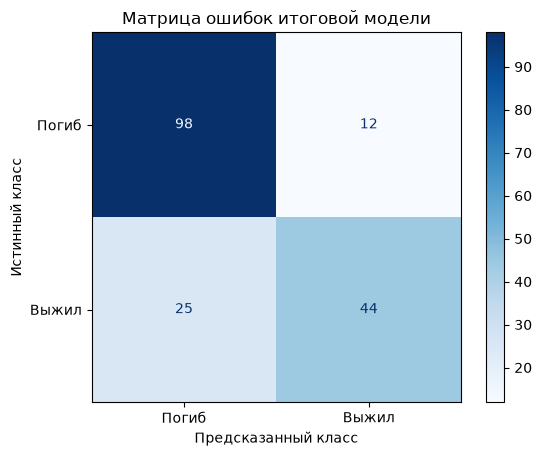

In [15]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_pred,
    display_labels=["Погиб", "Выжил"],
    cmap="Blues"
)

plt.title("Матрица ошибок итоговой модели")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.show()

## Итоговый отчёт

1. В работе использован датасет Titanic для бинарной классификации выживания пассажиров.

2. Обучены три модели: DecisionTreeClassifier, базовый RandomForestClassifier и случайный лес с настроенными гиперпараметрами.

3. Для подбора параметров использовалась GridSearchCV с пятикратной стратифицированной кросс-валидацией. Проверялись значения n_estimators, max_depth и min_samples_leaf.

4. Модели сравнивались по Accuracy, Precision, Recall и F1. Основной метрикой при настройке выбран F1.

5. Для интерпретации случайного леса построен график permutation importance.

6. Выполнен эксперимент по удалению двух наименее важных признаков. Качество полного и сокращённого наборов сравнивалось с помощью кросс-валидации.

7. Итоговый набор признаков выбран на основе результатов эксперимента и проверен на тестовой выборке.

### Заключение

Случайный лес объединяет несколько деревьев решений и может обеспечивать более устойчивые предсказания по сравнению с одиночным деревом.

Настройка гиперпараметров позволяет контролировать сложность ансамбля. Анализ важности признаков помогает исследовать возможность упрощения модели.

Окончательный вывод о предпочтительной модели и удаляемых признаках необходимо сделать по полученным метрикам.